# Conecta Sangue — Disciplina 2: Análise de Dados (Python)

**Projeto em Gestão de Sistemas Computacionais · 2026**

Este notebook transforma os cadastros do protótipo do Conecta Sangue em indicadores que medem as duas metas SMART do Termo de Abertura do Projeto (TAP), definidas na Disciplina 1:

| Problema (TAP) | Meta SMART | KPIs que medem a meta |
|---|---|---|
| Localização e mobilidade dos doadores | Permitir que 100% dos usuários e pontos de coleta cadastrados sejam localizados no sistema até a entrega final do projeto | KPI 1 e KPI 2 |
| Segurança dos dados | Garantir mecanismos de controle de acesso em 100% das funcionalidades que armazenam dados dos doadores | KPI 3 |

**Como executar:** no Google Colab, use *Ambiente de execução → Executar tudo*. Não é preciso instalar nada: todas as bibliotecas usadas já vêm no Colab. A primeira célula de dados gera a base simulada em `dados/brutos/`; o ETL grava os dados tratados em `dados/tratados/` e os gráficos são salvos em `graficos/`.

**Roteiro:** Etapa 0 (base simulada) → 2.1 ETL e KPIs → 2.2 Métodos estatísticos → 2.3 Visualização de dados → 2.4 Análise crítica.

In [1]:
# Bibliotecas utilizadas (todas já instaladas no Google Colab)
import os
import numpy as np                    # cálculos numéricos e geração da base simulada
import pandas as pd                   # leitura, limpeza e agregação dos dados (ETL)
import matplotlib
import matplotlib.pyplot as plt       # construção dos gráficos
import matplotlib.ticker as mtick     # formatação de eixos em %
import seaborn as sns                 # gráficos estatísticos (histograma, boxplot, dispersão)
import scipy
from scipy import stats               # assimetria, normalidade, correlação e qui-quadrado

pd.set_option('display.max_columns', 20)
pd.set_option('display.width', 130)

# Pastas do projeto
PASTA_BRUTOS = 'dados/brutos'
PASTA_TRATADOS = 'dados/tratados'
PASTA_GRAFICOS = 'graficos'
for pasta in [PASTA_BRUTOS, PASTA_TRATADOS, PASTA_GRAFICOS]:
    os.makedirs(pasta, exist_ok=True)

# Metas definidas na TAP (Disciplina 1)
META_LOCALIZACAO = 1.00       # 100% dos usuários e pontos de coleta localizados
META_CONTROLE_ACESSO = 1.00   # 100% das funcionalidades com dados de doadores com controle de acesso

# Limites geográficos da área de atuação do piloto
AREA = {'lat_min': -23.81, 'lat_max': -23.35, 'lon_min': -46.88, 'lon_max': -46.33}

print('Versões -> pandas', pd.__version__, '| numpy', np.__version__, '| scipy', scipy.__version__,
      '| matplotlib', matplotlib.__version__, '| seaborn', sns.__version__)

Versões -> pandas 3.0.5 | numpy 2.5.3 | scipy 1.18.1 | matplotlib 3.11.2 | seaborn 0.13.2


## Etapa 0 — Base de dados simulada

O protótipo ainda não tem usuários reais, e cadastros de doadores de sangue reúnem dados pessoais protegidos pela LGPD (Lei 13.709/2018). Por isso, a análise usa uma **base simulada** que reproduz o banco de dados do protótipo e os problemas típicos de cadastro: registros duplicados, CEP inválido, textos despadronizados, datas em formatos diferentes e coordenadas erradas.

A base segue a minimização de dados: não há nome, CPF, telefone ou e-mail. Cada doador é identificado apenas por um código (pseudonimização), e só existem os campos necessários para medir as metas da TAP.

| Arquivo | Conteúdo |
|---|---|
| `doadores_cadastros.csv` | cadastros de doadores feitos entre agosto e outubro de 2026: canal de cadastro, zona, idade, CEP, endereço completo, consentimento de localização, coordenadas e interação com campanhas |
| `pontos_coleta.csv` | hemocentros, postos fixos e unidades móveis de campanha cadastrados no sistema |
| `funcionalidades_prototipo.csv` | inventário das funcionalidades do protótipo e dos controles de acesso de cada uma |

O gerador usa uma semente fixa (`RandomState`, cujo gerador o NumPy mantém inalterado entre versões), então a base é sempre a mesma, no Colab ou em qualquer computador. Se os arquivos já existirem em `dados/brutos/` (por exemplo, editados pelo grupo), eles são usados sem alteração.

In [2]:
def gerar_base_simulada(pasta='dados/brutos', semente=2026):
    """Gera os três arquivos CSV da base simulada do protótipo Conecta Sangue.

    Usa np.random.RandomState, cujo gerador é congelado pelo NumPy: a mesma
    semente produz exatamente os mesmos dados em qualquer versão (Colab ou local).
    """
    rs = np.random.RandomState(semente)
    os.makedirs(pasta, exist_ok=True)

    # Área piloto simulada: posições em km a partir de um ponto de referência
    LAT0, LON0 = -23.5505, -46.6333
    KM_LAT = 111.0
    KM_LON = 111.0 * np.cos(np.radians(LAT0))
    X_MIN, X_MAX, Y_MIN, Y_MAX = -25, 30, -28, 22          # limites da área (km)

    def para_latlon(x, y):
        return LAT0 + y / KM_LAT, LON0 + x / KM_LON

    centro_zona = {'Centro': (0, 0, 2.0), 'Norte': (0, 10, 3.5), 'Sul': (-1, -13, 4.0),
                   'Leste': (15, -1, 4.5), 'Oeste': (-11, 1, 3.5)}

    def novo_cep():
        return '0' + ''.join(str(d) for d in rs.randint(0, 10, 7))

    def formatar_cep(c):
        return c[:5] + '-' + c[5:] if rs.rand() < 0.6 else c

    def sim_nao(valor):
        variantes = {'Sim': ['Sim', 'sim', 'SIM', 'S'], 'Não': ['Não', 'não', 'Nao', 'NÃO', 'N']}
        opcoes = variantes[valor]
        return opcoes[0] if rs.rand() < 0.8 else opcoes[rs.randint(1, len(opcoes))]

    def sujar_texto(valor, variantes):
        return valor if rs.rand() < 0.85 else variantes[rs.randint(0, len(variantes))]

    # ------------------------------------------------------------------
    # 1) Pontos de coleta
    # ------------------------------------------------------------------
    composicao = [  # zona, hemocentros, postos fixos, unidades móveis
        ('Centro', 1, 6, 2), ('Oeste', 1, 4, 2), ('Norte', 1, 4, 2),
        ('Sul', 0, 3, 4), ('Leste', 0, 3, 3)]
    # pontos cadastrados sem localização válida: (zona, tipo, ordem, problema)
    falhas_ponto = {('Sul', 'Unidade móvel', 1): 'sem_coord', ('Sul', 'Unidade móvel', 3): 'sem_coord',
                    ('Leste', 'Unidade móvel', 1): 'sem_coord', ('Leste', 'Unidade móvel', 2): 'sem_coord',
                    ('Norte', 'Unidade móvel', 2): 'sem_coord', ('Sul', 'Posto fixo', 3): 'cep_invalido',
                    ('Leste', 'Posto fixo', 3): 'invertida'}
    pontos = []
    n = 1
    for zona, n_hemo, n_posto, n_movel in composicao:
        cx, cy, sd = centro_zona[zona]
        for tipo, qtd, disp in [('Hemocentro', n_hemo, 0.3), ('Posto fixo', n_posto, 0.6),
                                ('Unidade móvel', n_movel, 1.3)]:
            for k in range(1, qtd + 1):
                x = float(np.clip(cx + rs.normal(0, sd * disp), X_MIN + 1, X_MAX - 1))
                y = float(np.clip(cy + rs.normal(0, sd * disp), Y_MIN + 1, Y_MAX - 1))
                lat, lon = para_latlon(x, y)
                problema = falhas_ponto.get((zona, tipo, k))
                cep, end, lat_s, lon_s = formatar_cep(novo_cep()), 'Sim', round(lat, 6), round(lon, 6)
                if problema == 'sem_coord':
                    end, lat_s, lon_s = 'Não', np.nan, np.nan
                elif problema == 'cep_invalido':
                    cep, lat_s, lon_s = '0' + ''.join(str(d) for d in rs.randint(0, 10, 4)), np.nan, np.nan
                elif problema == 'invertida':
                    lat_s, lon_s = round(lon, 6), round(lat, 6)
                nome = f'Hemocentro {zona}' if tipo == 'Hemocentro' else f'{tipo} {zona} {k:02d}'
                pontos.append({'id_ponto': f'P{n:03d}', 'nome_ponto': nome,
                               'tipo': sujar_texto(tipo, [tipo.lower(), tipo.upper(), tipo.replace('ó', 'o')]),
                               'zona': sujar_texto(zona, [zona.lower(), zona + ' ', zona.upper()]),
                               'cep': cep, 'endereco_completo': sim_nao(end),
                               'latitude': lat_s, 'longitude': lon_s})
                n += 1
    df_pontos = pd.DataFrame(pontos)
    # duas linhas duplicadas (exportação repetida)
    df_pontos = pd.concat([df_pontos, df_pontos.iloc[[4, 20]]], ignore_index=True)
    # duas coordenadas gravadas com vírgula decimal
    df_pontos['latitude'] = df_pontos['latitude'].astype(object)
    for i in [2, 11]:
        df_pontos.at[i, 'latitude'] = str(df_pontos.at[i, 'latitude']).replace('.', ',')

    # posições reais (no sistema) dos pontos localizáveis, usadas no comportamento dos doadores
    loc_pontos = []
    for p in pontos:
        la, lo = p['latitude'], p['longitude']
        if isinstance(la, float) and not np.isnan(la) and -23.81 <= la <= -23.35 and -46.88 <= lo <= -46.33:
            loc_pontos.append((la, lo))
    loc_pontos = np.array(loc_pontos)

    def dist_ponto_mais_proximo(lat, lon):
        R = 6371.0
        la1, lo1 = np.radians(lat), np.radians(lon)
        la2, lo2 = np.radians(loc_pontos[:, 0]), np.radians(loc_pontos[:, 1])
        a = np.sin((la2 - la1) / 2) ** 2 + np.cos(la1) * np.cos(la2) * np.sin((lo2 - lo1) / 2) ** 2
        return float((2 * R * np.arcsin(np.sqrt(a))).min())

    # ------------------------------------------------------------------
    # 2) Cadastros de doadores
    # ------------------------------------------------------------------
    N = 1200
    canais = ['App', 'Site', 'Campanha presencial']
    prob_canal = {8: [0.58, 0.27, 0.15], 9: [0.45, 0.25, 0.30], 10: [0.36, 0.22, 0.42]}
    zonas = ['Leste', 'Sul', 'Norte', 'Centro', 'Oeste']
    prob_zona = {'App': [0.24, 0.20, 0.19, 0.18, 0.19], 'Site': [0.24, 0.20, 0.19, 0.18, 0.19],
                 'Campanha presencial': [0.38, 0.28, 0.16, 0.08, 0.10]}
    prob_falha = {'App': 0.07, 'Site': 0.21, 'Campanha presencial': 0.50}
    motivos = ['consentimento', 'coordenada', 'cep', 'endereco']
    prob_motivo = {'App': [0.55, 0.30, 0.10, 0.05], 'Site': [0.12, 0.08, 0.45, 0.35],
                   'Campanha presencial': [0.03, 0.04, 0.55, 0.38]}
    inicio = pd.Timestamp('2026-08-01')
    fim = pd.Timestamp('2026-10-31')
    dias_mes = {8: (0, 30), 9: (31, 60), 10: (61, 91)}

    linhas = []
    for i in range(1, N + 1):
        mes = [8, 9, 10][rs.choice(3, p=[0.30, 0.33, 0.37])]
        d0, d1 = dias_mes[mes]
        data = inicio + pd.Timedelta(days=int(rs.randint(d0, d1 + 1)))
        canal = canais[rs.choice(3, p=prob_canal[mes])]
        zona = zonas[rs.choice(5, p=prob_zona[canal])]
        cx, cy, sd = centro_zona[zona]
        x = float(np.clip(cx + rs.normal(0, sd), X_MIN + 0.5, X_MAX - 0.5))
        y = float(np.clip(cy + rs.normal(0, sd), Y_MIN + 0.5, Y_MAX - 0.5))
        lat, lon = para_latlon(x, y)
        idade = int(np.clip(round(rs.normal(34, 11)), 16, 69))
        cep, end, cons = formatar_cep(novo_cep()), 'Sim', 'Sim'
        lat_s, lon_s = round(lat + rs.normal(0, 0.0004), 6), round(lon + rs.normal(0, 0.0004), 6)
        localizado = rs.rand() >= prob_falha[canal]
        if not localizado:
            motivo = motivos[rs.choice(4, p=prob_motivo[canal])]
            if motivo == 'consentimento':
                cons, lat_s, lon_s = 'Não', np.nan, np.nan
            elif motivo == 'cep':
                r = rs.rand()
                cep = np.nan if r < 0.4 else ('00000-000' if r < 0.6 else
                                              '0' + ''.join(str(d) for d in rs.randint(0, 10, rs.randint(3, 6))))
                lat_s, lon_s = np.nan, np.nan
            elif motivo == 'endereco':
                end, lat_s, lon_s = 'Não', np.nan, np.nan
            else:  # coordenada gravada fora da área de atuação
                r = rs.rand()
                if r < 0.4:
                    lat_s, lon_s = 0.0, 0.0
                elif r < 0.8:
                    lat_s, lon_s = lon_s, lat_s
                else:
                    lat_s = -lat_s
        # comportamento nas campanhas de doação (período até 31/10)
        meses_ativos = (fim - data).days / 30 + 0.5
        if localizado:
            dist = dist_ponto_mais_proximo(lat, lon)
            notif = rs.poisson(2.0 * meses_ativos + 1.0)
            p_conf = 0.06 + 0.38 * np.exp(-dist / 4.5)
        else:
            notif = rs.poisson(0.7 * meses_ativos + 0.3)
            p_conf = 0.10
        conf = rs.binomial(notif, p_conf) if notif > 0 else 0
        data_txt = data.strftime('%d/%m/%Y') if rs.rand() < 0.35 else data.strftime('%Y-%m-%d')
        linhas.append({'id_doador': f'D{i:05d}', 'data_cadastro': data_txt,
                       'canal_cadastro': sujar_texto(canal, [canal.lower(), canal.upper(), ' ' + canal + ' ',
                                                             canal.title()]),
                       'zona': sujar_texto(zona, [zona.lower(), zona + ' ', zona.upper()]),
                       'idade': idade, 'cep': cep, 'endereco_completo': sim_nao(end),
                       'consentimento_localizacao': sim_nao(cons),
                       'latitude': lat_s, 'longitude': lon_s,
                       'notificacoes_campanha': notif, 'confirmacoes_interesse': conf})
    df_doadores = pd.DataFrame(linhas)

    # problemas típicos de exportação e digitação
    df_doadores['idade'] = df_doadores['idade'].astype(object)
    idx = rs.choice(N, 27, replace=False)
    for j, k in enumerate(idx):
        df_doadores.at[k, 'idade'] = np.nan if j < 15 else [0, 7, 120, 150, 999, -1][j % 6]
    for col, qtd in [('notificacoes_campanha', 10), ('confirmacoes_interesse', 8)]:
        df_doadores[col] = df_doadores[col].astype(object)
        for k in rs.choice(N, qtd, replace=False):
            df_doadores.at[k, col] = np.nan
    for k in rs.choice(N, 6, replace=False):  # confirmação maior que notificação (erro de integração)
        notif = df_doadores.at[k, 'notificacoes_campanha']
        if pd.notna(notif):
            df_doadores.at[k, 'confirmacoes_interesse'] = int(notif) + int(rs.randint(1, 4))
    df_doadores['latitude'] = df_doadores['latitude'].astype(object)
    df_doadores['longitude'] = df_doadores['longitude'].astype(object)
    for k in rs.choice(N, 30, replace=False):  # vírgula como separador decimal
        if pd.notna(df_doadores.at[k, 'latitude']):
            df_doadores.at[k, 'latitude'] = str(df_doadores.at[k, 'latitude']).replace('.', ',')
            df_doadores.at[k, 'longitude'] = str(df_doadores.at[k, 'longitude']).replace('.', ',')
    duplicadas = df_doadores.iloc[np.sort(rs.choice(N, 36, replace=False))]
    df_doadores = pd.concat([df_doadores, duplicadas], ignore_index=True)

    # ------------------------------------------------------------------
    # 3) Funcionalidades do protótipo (inventário de controle de acesso)
    # ------------------------------------------------------------------
    funcs = [
        ('F01', 'Perfil do doador (visualizar e editar)', 'Cadastro', 'Sim', 'Sim', 'Sim'),
        ('F02', 'Endereço e CEP do doador', 'Cadastro', 'Sim', 'Sim', 'Sim'),
        ('F03', 'Consentimento de localização (LGPD)', 'Cadastro', 'Sim', 'Sim', 'Sim'),
        ('F04', 'Busca de pontos de coleta próximos', 'Localização', 'Sim', 'Não', 'Não'),
        ('F05', 'Mapa público de pontos de coleta', 'Localização', 'Não', 'Não', 'Não'),
        ('F06', 'Cadastro de ponto de coleta', 'Pontos de coleta', 'Não', 'Sim', 'Sim'),
        ('F07', 'Edição de ponto de coleta', 'Pontos de coleta', 'Não', 'Sim', 'Sim'),
        ('F08', 'Publicação de campanha', 'Campanhas', 'Não', 'Sim', 'Sim'),
        ('F09', 'Notificação de campanha por proximidade', 'Campanhas', 'Sim', 'Não', 'Não'),
        ('F10', 'Confirmação de interesse em campanha', 'Campanhas', 'Sim', 'Sim', 'Não'),
        ('F11', 'Painel administrativo de doadores', 'Administração', 'Sim', 'Sim', 'Sim'),
        ('F12', 'Exportação de relatório de doadores', 'Administração', 'Sim', 'Sim', 'Não'),
        ('F13', 'Histórico de notificações do doador', 'Campanhas', 'Sim', 'Não', 'Não'),
        ('F14', 'Exclusão de conta e dados (direito do titular)', 'Conta', 'Sim', 'Sim', 'Sim'),
        ('F15', 'Recuperação de senha', 'Conta', 'Sim', 'Sim', 'Sim'),
        ('F16', 'Página pública de campanhas', 'Campanhas', 'Não', 'Não', 'Não'),
    ]
    df_funcs = pd.DataFrame(funcs, columns=['id_funcionalidade', 'funcionalidade', 'modulo',
                                            'armazena_dados_doador', 'exige_autenticacao',
                                            'autorizacao_por_perfil'])
    for col in ['armazena_dados_doador', 'exige_autenticacao', 'autorizacao_por_perfil']:
        df_funcs[col] = [sim_nao(v) for v in df_funcs[col]]

    df_doadores.to_csv(f'{pasta}/doadores_cadastros.csv', index=False)
    df_pontos.to_csv(f'{pasta}/pontos_coleta.csv', index=False)
    df_funcs.to_csv(f'{pasta}/funcionalidades_prototipo.csv', index=False)
    return df_doadores, df_pontos, df_funcs


ARQUIVOS = {'doadores': f'{PASTA_BRUTOS}/doadores_cadastros.csv',
            'pontos': f'{PASTA_BRUTOS}/pontos_coleta.csv',
            'funcionalidades': f'{PASTA_BRUTOS}/funcionalidades_prototipo.csv'}

if all(os.path.exists(caminho) for caminho in ARQUIVOS.values()):
    print('Base encontrada em dados/brutos/ — usando os arquivos existentes.')
else:
    gerar_base_simulada(PASTA_BRUTOS)
    print('Base simulada gerada em dados/brutos/.')

Base simulada gerada em dados/brutos/.


---
## 2.1 Tratamento de dados (ETL) e justificativa dos KPIs

### Extração

Todos os arquivos são lidos como texto. Assim, nenhum valor é convertido antes de ser validado, e o CEP mantém os zeros à esquerda.

In [3]:
# EXTRAÇÃO
doadores_bruto = pd.read_csv(ARQUIVOS['doadores'], dtype=str)
pontos_bruto = pd.read_csv(ARQUIVOS['pontos'], dtype=str)
funcs_bruto = pd.read_csv(ARQUIVOS['funcionalidades'], dtype=str)


def diagnostico(df, chave):
    """Resumo de qualidade: linhas, duplicatas pelo identificador e células vazias."""
    return pd.Series({'linhas': len(df),
                      'duplicatas (mesmo id)': int(df.duplicated(subset=chave).sum()),
                      'células vazias': int(df.isna().sum().sum())})


print('Diagnóstico de qualidade ANTES do tratamento:')
display(pd.DataFrame({'doadores': diagnostico(doadores_bruto, 'id_doador'),
                      'pontos de coleta': diagnostico(pontos_bruto, 'id_ponto'),
                      'funcionalidades': diagnostico(funcs_bruto, 'id_funcionalidade')}))

print('Células vazias por coluna (doadores):')
display(doadores_bruto.isna().sum().to_frame('vazias').T)

print('Valores distintos encontrados antes da padronização:')
for coluna in ['canal_cadastro', 'zona', 'consentimento_localizacao']:
    print(f'  {coluna}: {sorted(doadores_bruto[coluna].dropna().unique())}')

display(doadores_bruto.head())

Diagnóstico de qualidade ANTES do tratamento:


,doadores,pontos de coleta,funcionalidades
linhas,1236,38,16
duplicatas (mesmo id),36,2,0
células vazias,610,12,0


Células vazias por coluna (doadores):


,id_doador,data_cadastro,canal_cadastro,zona,idade,cep,endereco_completo,consentimento_localizacao,latitude,longitude,notificacoes_campanha,confirmacoes_interesse
vazias,0,0,0,0,15,62,0,0,257,257,11,8


Valores distintos encontrados antes da padronização:
  canal_cadastro: [' App ', ' Campanha presencial ', ' Site ', 'APP', 'App', 'CAMPANHA PRESENCIAL', 'Campanha Presencial', 'Campanha presencial', 'SITE', 'Site', 'app', 'campanha presencial', 'site']
  zona: ['CENTRO', 'Centro', 'Centro ', 'LESTE', 'Leste', 'Leste ', 'NORTE', 'Norte', 'Norte ', 'OESTE', 'Oeste', 'Oeste ', 'SUL', 'Sul', 'Sul ', 'centro', 'leste', 'norte', 'oeste', 'sul']
  consentimento_localizacao: ['N', 'Nao', 'NÃO', 'Não', 'S', 'SIM', 'Sim', 'não', 'sim']


,id_doador,data_cadastro,canal_cadastro,zona,idade,cep,endereco_completo,consentimento_localizacao,latitude,longitude,notificacoes_campanha,confirmacoes_interesse
0,D00001,2026-09-14,App,Leste,28,03034-428,Sim,Sim,-23.543674,-46.54913,NaN,1
1,D00002,29/10/2026,App,Oeste,37,06802-650,S,sim,-23.474359,-46.790925,2,0
2,D00003,2026-08-20,App,Leste,69,09770207,S,Sim,-23.547472,-46.520341,12,4
3,D00004,2026-09-12,Campanha presencial,Leste,27,03874-476,N,Sim,NaN,NaN,1,0
4,D00005,20/09/2026,App,Leste,38,05202-257,Sim,sim,-23.56347,-46.520206,2,1


### Transformação — regras aplicadas

| # | Regra | Justificativa |
|---|---|---|
| 1 | Remover duplicatas pelo identificador | Exportações repetidas inflariam os denominadores dos KPIs. |
| 2 | Padronizar textos (canal, zona, tipo de ponto, respostas Sim/Não) | "app", " App " e "APP" seriam contados como canais diferentes. |
| 3 | Converter datas nos formatos aaaa-mm-dd e dd/mm/aaaa | Permite acompanhar o KPI ao longo do tempo. |
| 4 | Validar o CEP (8 dígitos e diferente de 00000-000) e padronizar no formato 00000-000 | O CEP é a base da geolocalização do cadastro. |
| 5 | Anular idades fora de 16 a 69 anos | É a faixa de idade permitida para doação (Ministério da Saúde); valores como 0 ou 999 são erro de digitação. |
| 6 | Converter coordenadas (vírgula → ponto) e invalidar as que caem fora da área de atuação | (0, 0), latitude e longitude trocadas ou com sinal invertido não localizam ninguém. |
| 7 | Interações com campanhas: vazio → 0; confirmações maiores que notificações → nulo | Ausência de registro significa nenhuma interação; confirmar mais avisos do que recebeu é erro de integração. |
| 8 | Criar `localizado`, `motivo_nao_localizado`, `distancia_km` e `taxa_resposta` | São as variáveis usadas nos KPIs e na análise estatística. |

In [4]:
# Funções de apoio ao ETL
MAPA_SIM_NAO = {'sim': 'Sim', 's': 'Sim', 'não': 'Não', 'nao': 'Não', 'n': 'Não'}
MAPA_CANAL = {'app': 'App', 'site': 'Site', 'campanha presencial': 'Campanha presencial'}
MAPA_ZONA = {'centro': 'Centro', 'norte': 'Norte', 'sul': 'Sul', 'leste': 'Leste', 'oeste': 'Oeste'}
MAPA_TIPO = {'hemocentro': 'Hemocentro', 'posto fixo': 'Posto fixo',
             'unidade móvel': 'Unidade móvel', 'unidade movel': 'Unidade móvel'}


def padronizar(serie, mapa):
    """Remove espaços nas pontas, ignora maiúsculas/minúsculas e aplica o mapa de valores válidos."""
    padronizada = serie.str.strip().str.lower().map(mapa)
    nao_mapeados = serie[padronizada.isna() & serie.notna()].unique()
    assert len(nao_mapeados) == 0, f'Valores sem regra de padronização: {nao_mapeados}'
    return padronizada


def validar_cep(serie):
    """Mantém só os dígitos; válido = 8 dígitos e diferente de 00000000."""
    digitos = serie.fillna('').str.replace(r'\D', '', regex=True)
    valido = (digitos.str.len() == 8) & (digitos != '00000000')
    formatado = (digitos.str[:5] + '-' + digitos.str[5:]).where(valido)
    return formatado, valido


def para_numero(serie):
    """Converte texto em número aceitando vírgula como separador decimal."""
    return pd.to_numeric(serie.str.replace(',', '.', regex=False), errors='coerce')


def converter_data(serie):
    """Aceita datas nos formatos aaaa-mm-dd e dd/mm/aaaa."""
    iso = pd.to_datetime(serie, format='%Y-%m-%d', errors='coerce')
    brasileiro = pd.to_datetime(serie, format='%d/%m/%Y', errors='coerce')
    return iso.fillna(brasileiro)


def dentro_da_area(lat, lon):
    """True quando a coordenada está dentro dos limites da área de atuação."""
    return (lat.between(AREA['lat_min'], AREA['lat_max'])
            & lon.between(AREA['lon_min'], AREA['lon_max']))


def distancia_km(lat1, lon1, lat2, lon2):
    """Distância em linha reta pela fórmula de Haversine, em km (aceita vetores e matrizes)."""
    raio_terra = 6371.0
    lat1, lon1, lat2, lon2 = map(np.radians, (lat1, lon1, lat2, lon2))
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 2 * raio_terra * np.arcsin(np.sqrt(a))


registro_etl = []   # o que cada regra alterou, para documentar o tratamento

In [5]:
# TRANSFORMAÇÃO — doadores
doadores = doadores_bruto.copy()

# Regra 1: duplicatas
antes = len(doadores)
doadores = doadores.drop_duplicates(subset='id_doador', keep='first').reset_index(drop=True)
registro_etl.append(('Doadores', 'Registros duplicados removidos', antes - len(doadores)))

# Regra 2: textos padronizados
for coluna, mapa in [('canal_cadastro', MAPA_CANAL), ('zona', MAPA_ZONA),
                     ('endereco_completo', MAPA_SIM_NAO), ('consentimento_localizacao', MAPA_SIM_NAO)]:
    padronizada = padronizar(doadores[coluna], mapa)
    corrigidos = int((padronizada != doadores[coluna]).sum())
    doadores[coluna] = padronizada
    registro_etl.append(('Doadores', f'Textos corrigidos em {coluna}', corrigidos))

# Regra 3: datas
formato_br = int(doadores['data_cadastro'].str.contains('/', na=False).sum())
doadores['data_cadastro'] = converter_data(doadores['data_cadastro'])
assert doadores['data_cadastro'].notna().all(), 'Há datas que não puderam ser convertidas'
registro_etl.append(('Doadores', 'Datas dd/mm/aaaa convertidas', formato_br))

# Regra 4: CEP
doadores['cep'], doadores['cep_valido'] = validar_cep(doadores['cep'])
registro_etl.append(('Doadores', 'CEPs ausentes ou inválidos', int((~doadores['cep_valido']).sum())))

# Regra 5: idade
doadores['idade'] = pd.to_numeric(doadores['idade'], errors='coerce')
idade_invalida = doadores['idade'].notna() & ~doadores['idade'].between(16, 69)
doadores.loc[idade_invalida, 'idade'] = np.nan
registro_etl.append(('Doadores', 'Idades fora de 16–69 anos anuladas', int(idade_invalida.sum())))

# Regra 6: coordenadas
com_virgula = int(doadores['latitude'].str.contains(',', na=False).sum())
doadores['latitude'] = para_numero(doadores['latitude'])
doadores['longitude'] = para_numero(doadores['longitude'])
doadores['coord_valida'] = dentro_da_area(doadores['latitude'], doadores['longitude'])
fora_da_area = doadores['latitude'].notna() & ~doadores['coord_valida']
registro_etl.append(('Doadores', 'Coordenadas com vírgula decimal convertidas', com_virgula))
registro_etl.append(('Doadores', 'Coordenadas fora da área de atuação invalidadas', int(fora_da_area.sum())))

# Regra 7: interações com campanhas
colunas_campanha = ['notificacoes_campanha', 'confirmacoes_interesse']
for coluna in colunas_campanha:
    doadores[coluna] = pd.to_numeric(doadores[coluna], errors='coerce')
vazios = int(doadores[colunas_campanha].isna().sum().sum())
doadores[colunas_campanha] = doadores[colunas_campanha].fillna(0)
inconsistentes = doadores['confirmacoes_interesse'] > doadores['notificacoes_campanha']
doadores.loc[inconsistentes, 'confirmacoes_interesse'] = np.nan
registro_etl.append(('Doadores', 'Interações vazias preenchidas com 0', vazios))
registro_etl.append(('Doadores', 'Confirmações maiores que notificações anuladas', int(inconsistentes.sum())))

# Regra 8: o doador está localizado? Se não, por quê? (a ordem define a causa)
condicoes = [doadores['consentimento_localizacao'] == 'Não',
             ~doadores['cep_valido'],
             doadores['endereco_completo'] == 'Não',
             ~doadores['coord_valida']]
causas = ['Sem consentimento de localização', 'CEP ausente ou inválido',
          'Endereço incompleto', 'Coordenada fora da área']
causa = np.select(condicoes, causas, default='')
doadores['localizado'] = causa == ''
doadores['motivo_nao_localizado'] = (pd.Series(causa, index=doadores.index)
                                     .where(~doadores['localizado']))
doadores.loc[~doadores['localizado'], ['latitude', 'longitude']] = np.nan

print(f'Doadores: {antes} linhas brutas -> {len(doadores)} cadastros únicos tratados')
display(doadores.head())

Doadores: 1236 linhas brutas -> 1200 cadastros únicos tratados


,id_doador,data_cadastro,canal_cadastro,zona,idade,cep,endereco_completo,consentimento_localizacao,latitude,longitude,notificacoes_campanha,confirmacoes_interesse,cep_valido,coord_valida,localizado,motivo_nao_localizado
0,D00001,2026-09-14,App,Leste,28.0,03034-428,Sim,Sim,-23.543674,-46.549130,0.0,NaN,True,True,True,NaN
1,D00002,2026-10-29,App,Oeste,37.0,06802-650,Sim,Sim,-23.474359,-46.790925,2.0,0.0,True,True,True,NaN
2,D00003,2026-08-20,App,Leste,69.0,09770-207,Sim,Sim,-23.547472,-46.520341,12.0,4.0,True,True,True,NaN
3,D00004,2026-09-12,Campanha presencial,Leste,27.0,03874-476,Não,Sim,NaN,NaN,1.0,0.0,True,False,False,Endereço incompleto
4,D00005,2026-09-20,App,Leste,38.0,05202-257,Sim,Sim,-23.563470,-46.520206,2.0,1.0,True,True,True,NaN


In [6]:
# TRANSFORMAÇÃO — pontos de coleta
pontos = pontos_bruto.copy()
antes_pontos = len(pontos)
pontos = pontos.drop_duplicates(subset='id_ponto', keep='first').reset_index(drop=True)
registro_etl.append(('Pontos de coleta', 'Registros duplicados removidos', antes_pontos - len(pontos)))

for coluna, mapa in [('tipo', MAPA_TIPO), ('zona', MAPA_ZONA), ('endereco_completo', MAPA_SIM_NAO)]:
    padronizada = padronizar(pontos[coluna], mapa)
    registro_etl.append(('Pontos de coleta', f'Textos corrigidos em {coluna}',
                         int((padronizada != pontos[coluna]).sum())))
    pontos[coluna] = padronizada

pontos['cep'], pontos['cep_valido'] = validar_cep(pontos['cep'])
pontos['latitude'] = para_numero(pontos['latitude'])
pontos['longitude'] = para_numero(pontos['longitude'])
pontos['coord_valida'] = dentro_da_area(pontos['latitude'], pontos['longitude'])

condicoes_ponto = [~pontos['cep_valido'], pontos['endereco_completo'] == 'Não', ~pontos['coord_valida']]
causas_ponto = ['CEP ausente ou inválido', 'Endereço incompleto', 'Coordenada ausente ou fora da área']
causa_ponto = np.select(condicoes_ponto, causas_ponto, default='')
pontos['localizado'] = causa_ponto == ''
pontos['motivo_nao_localizado'] = pd.Series(causa_ponto, index=pontos.index).where(~pontos['localizado'])
pontos.loc[~pontos['localizado'], ['latitude', 'longitude']] = np.nan
registro_etl.append(('Pontos de coleta', 'Pontos sem localização válida', int((~pontos['localizado']).sum())))

print(f'Pontos de coleta: {antes_pontos} linhas brutas -> {len(pontos)} pontos únicos tratados')
display(pontos[['id_ponto', 'nome_ponto', 'tipo', 'zona', 'cep', 'localizado', 'motivo_nao_localizado']])

Pontos de coleta: 38 linhas brutas -> 36 pontos únicos tratados


,id_ponto,nome_ponto,tipo,zona,cep,localizado,motivo_nao_localizado
0,P001,Hemocentro Centro,Hemocentro,Centro,04352-609,True,NaN
1,P002,Posto fixo Centro 01,Posto fixo,Centro,01944-966,True,NaN
2,P003,Posto fixo Centro 02,Posto fixo,Centro,02387-396,True,NaN
3,P004,Posto fixo Centro 03,Posto fixo,Centro,07072-440,True,NaN
4,P005,Posto fixo Centro 04,Posto fixo,Centro,09575-797,True,NaN
5,P006,Posto fixo Centro 05,Posto fixo,Centro,01466-206,True,NaN
6,P007,Posto fixo Centro 06,Posto fixo,Centro,01546-539,True,NaN
7,P008,Unidade móvel Centro 01,Unidade móvel,Centro,08900-617,True,NaN
8,P009,Unidade móvel Centro 02,Unidade móvel,Centro,04291-690,True,NaN
9,P010,Hemocentro Oeste,Hemocentro,Oeste,03669-864,True,NaN


In [7]:
# Regra 8 (continuação): distância até o ponto localizado mais próximo e taxa de resposta
pontos_localizados = pontos[pontos['localizado']].reset_index(drop=True)
loc = doadores['localizado'].to_numpy()

matriz = distancia_km(doadores.loc[loc, 'latitude'].to_numpy()[:, None],
                      doadores.loc[loc, 'longitude'].to_numpy()[:, None],
                      pontos_localizados['latitude'].to_numpy()[None, :],
                      pontos_localizados['longitude'].to_numpy()[None, :])

distancia = np.full(len(doadores), np.nan)
distancia[loc] = matriz.min(axis=1)
doadores['distancia_km'] = distancia.round(2)

mais_proximo = np.full(len(doadores), None, dtype=object)
mais_proximo[loc] = pontos_localizados['id_ponto'].to_numpy()[matriz.argmin(axis=1)]
doadores['ponto_mais_proximo'] = mais_proximo

# Taxa de resposta às campanhas = confirmações de interesse / notificações recebidas
notificacoes_validas = doadores['notificacoes_campanha'].where(doadores['notificacoes_campanha'] > 0)
doadores['taxa_resposta'] = doadores['confirmacoes_interesse'] / notificacoes_validas

print(f'Distância calculada para {loc.sum()} doadores localizados, '
      f'usando {len(pontos_localizados)} pontos de coleta localizados.')
display(doadores.loc[loc, ['id_doador', 'zona', 'distancia_km', 'ponto_mais_proximo',
                           'notificacoes_campanha', 'confirmacoes_interesse', 'taxa_resposta']].head())

Distância calculada para 929 doadores localizados, usando 29 pontos de coleta localizados.


,id_doador,zona,distancia_km,ponto_mais_proximo,notificacoes_campanha,confirmacoes_interesse,taxa_resposta
0,D00001,Leste,1.91,P036,0.0,NaN,NaN
1,D00002,Oeste,4.25,P015,2.0,0.0,0.000000
2,D00003,Leste,0.97,P032,12.0,4.0,0.333333
4,D00005,Leste,1.39,P032,2.0,1.0,0.500000
5,D00006,Oeste,2.26,P012,8.0,2.0,0.250000


In [8]:
# TRANSFORMAÇÃO — funcionalidades do protótipo
funcionalidades = funcs_bruto.drop_duplicates(subset='id_funcionalidade').reset_index(drop=True)
for coluna in ['armazena_dados_doador', 'exige_autenticacao', 'autorizacao_por_perfil']:
    padronizada = padronizar(funcionalidades[coluna], MAPA_SIM_NAO)
    registro_etl.append(('Funcionalidades', f'Textos corrigidos em {coluna}',
                         int((padronizada != funcionalidades[coluna]).sum())))
    funcionalidades[coluna] = padronizada

# Controle de acesso = autenticação (quem é) + autorização por perfil (o que pode fazer)
funcionalidades['controle_acesso'] = (
    (funcionalidades['exige_autenticacao'] == 'Sim')
    & (funcionalidades['autorizacao_por_perfil'] == 'Sim'))
display(funcionalidades)

,id_funcionalidade,funcionalidade,modulo,armazena_dados_doador,exige_autenticacao,autorizacao_por_perfil,controle_acesso
0,F01,Perfil do doador (visualizar e editar),Cadastro,Sim,Sim,Sim,True
1,F02,Endereço e CEP do doador,Cadastro,Sim,Sim,Sim,True
2,F03,Consentimento de localização (LGPD),Cadastro,Sim,Sim,Sim,True
3,F04,Busca de pontos de coleta próximos,Localização,Sim,Não,Não,False
4,F05,Mapa público de pontos de coleta,Localização,Não,Não,Não,False
5,F06,Cadastro de ponto de coleta,Pontos de coleta,Não,Sim,Sim,True
6,F07,Edição de ponto de coleta,Pontos de coleta,Não,Sim,Sim,True
7,F08,Publicação de campanha,Campanhas,Não,Sim,Sim,True
8,F09,Notificação de campanha por proximidade,Campanhas,Sim,Não,Não,False
9,F10,Confirmação de interesse em campanha,Campanhas,Sim,Sim,Não,False


### Carga

Os dados tratados são gravados em `dados/tratados/` (UTF-8 com BOM, para abrir sem erros de acentuação no Excel). A tabela abaixo documenta tudo o que o ETL alterou.

In [9]:
# CARGA
doadores.to_csv(f'{PASTA_TRATADOS}/doadores_tratados.csv', index=False, encoding='utf-8-sig')
pontos.to_csv(f'{PASTA_TRATADOS}/pontos_coleta_tratados.csv', index=False, encoding='utf-8-sig')
funcionalidades.to_csv(f'{PASTA_TRATADOS}/funcionalidades_tratadas.csv', index=False, encoding='utf-8-sig')

tabela_etl = pd.DataFrame(registro_etl, columns=['Base', 'Tratamento', 'Registros afetados'])
display(tabela_etl)
print('Arquivos gravados em dados/tratados/:', sorted(os.listdir(PASTA_TRATADOS)))

,Base,Tratamento,Registros afetados
0,Doadores,Registros duplicados removidos,36
1,Doadores,Textos corrigidos em canal_cadastro,153
2,Doadores,Textos corrigidos em zona,174
3,Doadores,Textos corrigidos em endereco_completo,243
4,Doadores,Textos corrigidos em consentimento_localizacao,248
5,Doadores,Datas dd/mm/aaaa convertidas,412
6,Doadores,CEPs ausentes ou inválidos,128
7,Doadores,Idades fora de 16–69 anos anuladas,12
8,Doadores,Coordenadas com vírgula decimal convertidas,24
9,Doadores,Coordenadas fora da área de atuação invalidadas,22


Arquivos gravados em dados/tratados/: ['doadores_tratados.csv', 'funcionalidades_tratadas.csv', 'pontos_coleta_tratados.csv']


### Cálculo dos KPIs

Cada KPI mede diretamente o progresso de uma meta SMART da TAP:

| KPI | Fórmula | Meta SMART que mede |
|---|---|---|
| **KPI 1 – Taxa de localização de doadores** | doadores localizados ÷ doadores cadastrados | Localização e mobilidade (100% dos usuários localizados) |
| **KPI 2 – Taxa de localização de pontos de coleta** | pontos localizados ÷ pontos cadastrados | Localização e mobilidade (100% dos pontos de coleta localizados) |
| **KPI 3 – Cobertura de controle de acesso** | funcionalidades com dados de doadores que exigem autenticação **e** autorização por perfil ÷ funcionalidades que armazenam dados de doadores | Segurança dos dados (100% das funcionalidades protegidas) |

Um registro só conta como **localizado** se tiver consentimento de localização, CEP válido, endereço completo e coordenada dentro da área de atuação.

In [10]:
def pct(valor, casas=1):
    """Formata proporção como porcentagem no padrão brasileiro (vírgula decimal)."""
    return f'{valor * 100:.{casas}f}%'.replace('.', ',')


def num(valor):
    """Formata inteiro com ponto como separador de milhar (1.200)."""
    return f'{int(valor):,}'.replace(',', '.')


funcs_com_dados = funcionalidades[funcionalidades['armazena_dados_doador'] == 'Sim']

kpis = pd.DataFrame({
    'KPI': ['KPI 1 – Taxa de localização de doadores',
            'KPI 2 – Taxa de localização de pontos de coleta',
            'KPI 3 – Cobertura de controle de acesso'],
    'Meta SMART (TAP)': ['Localização e mobilidade', 'Localização e mobilidade',
                         'Segurança dos dados'],
    'Atendidos': [int(doadores['localizado'].sum()), int(pontos['localizado'].sum()),
                  int(funcs_com_dados['controle_acesso'].sum())],
    'Total': [len(doadores), len(pontos), len(funcs_com_dados)],
    'Meta': [META_LOCALIZACAO, META_LOCALIZACAO, META_CONTROLE_ACESSO]})
kpis['Resultado'] = kpis['Atendidos'] / kpis['Total']
kpis['Faltam para a meta'] = ((kpis['Meta'] * kpis['Total']).round().astype(int)
                              - kpis['Atendidos'])
kpis['Distância da meta (p.p.)'] = ((kpis['Meta'] - kpis['Resultado']) * 100).round(1)

exibicao = kpis.copy()
exibicao['Resultado'] = exibicao['Resultado'].map(pct)
exibicao['Meta'] = exibicao['Meta'].map(lambda v: pct(v, 0))
display(exibicao[['KPI', 'Meta SMART (TAP)', 'Atendidos', 'Total', 'Resultado', 'Meta',
                  'Faltam para a meta', 'Distância da meta (p.p.)']])

print('Funcionalidades com dados de doadores SEM controle de acesso completo:')
for _, linha in funcs_com_dados[~funcs_com_dados['controle_acesso']].iterrows():
    print(f"  {linha['id_funcionalidade']} – {linha['funcionalidade']} "
          f"(autenticação: {linha['exige_autenticacao']}, autorização por perfil: {linha['autorizacao_por_perfil']})")

,KPI,Meta SMART (TAP),Atendidos,Total,Resultado,Meta,Faltam para a meta,Distância da meta (p.p.)
0,KPI 1 – Taxa de localização de doadores,Localização e mobilidade,929,1200,"77,4%",100%,271,22.6
1,KPI 2 – Taxa de localização de pontos de coleta,Localização e mobilidade,29,36,"80,6%",100%,7,19.4
2,KPI 3 – Cobertura de controle de acesso,Segurança dos dados,6,11,"54,5%",100%,5,45.5


Funcionalidades com dados de doadores SEM controle de acesso completo:
  F04 – Busca de pontos de coleta próximos (autenticação: Não, autorização por perfil: Não)
  F09 – Notificação de campanha por proximidade (autenticação: Não, autorização por perfil: Não)
  F10 – Confirmação de interesse em campanha (autenticação: Sim, autorização por perfil: Não)
  F12 – Exportação de relatório de doadores (autenticação: Sim, autorização por perfil: Não)
  F13 – Histórico de notificações do doador (autenticação: Não, autorização por perfil: Não)


In [11]:
# Onde está a diferença para a meta? KPI 1 aberto por canal, zona e período
def taxa_por(grupo):
    tabela = doadores.groupby(grupo).agg(cadastros=('id_doador', 'count'),
                                         localizados=('localizado', 'sum'))
    tabela['nao_localizados'] = tabela['cadastros'] - tabela['localizados']
    tabela['taxa_localizacao'] = tabela['localizados'] / tabela['cadastros']
    tabela['participacao_nos_cadastros'] = tabela['cadastros'] / tabela['cadastros'].sum()
    tabela['participacao_nos_nao_localizados'] = tabela['nao_localizados'] / tabela['nao_localizados'].sum()
    return tabela.sort_values('taxa_localizacao')


def formatar(tabela):
    saida = tabela.copy()
    for coluna in saida.columns:
        if coluna.startswith(('taxa', 'participacao', 'acumulado')):
            saida[coluna] = saida[coluna].map(pct)
    return saida


kpi1_canal = taxa_por('canal_cadastro')
kpi1_zona = taxa_por('zona')
print('KPI 1 por canal de cadastro:')
display(formatar(kpi1_canal))
print('KPI 1 por zona:')
display(formatar(kpi1_zona))

motivos = (doadores['motivo_nao_localizado'].value_counts()
           .rename_axis('motivo').reset_index(name='doadores'))
motivos['participacao'] = motivos['doadores'] / motivos['doadores'].sum()
motivos['acumulado'] = motivos['participacao'].cumsum()
print('Motivos de não localização (doadores):')
display(formatar(motivos))

print('KPI 2 por tipo de ponto de coleta:')
kpi2_tipo = pontos.groupby('tipo').agg(pontos=('id_ponto', 'count'), localizados=('localizado', 'sum'))
kpi2_tipo['taxa_localizacao'] = kpi2_tipo['localizados'] / kpi2_tipo['pontos']
display(formatar(kpi2_tipo))
print('Pontos de coleta localizados por zona:')
pontos_zona = pontos.groupby('zona').agg(pontos=('id_ponto', 'count'), localizados=('localizado', 'sum'))
display(pontos_zona)

KPI 1 por canal de cadastro:


,cadastros,localizados,nao_localizados,taxa_localizacao,participacao_nos_cadastros,participacao_nos_nao_localizados
canal_cadastro,,,,,,
Campanha presencial,365,196,169,"53,7%","30,4%","62,4%"
Site,304,242,62,"79,6%","25,3%","22,9%"
App,531,491,40,"92,5%","44,2%","14,8%"


KPI 1 por zona:


,cadastros,localizados,nao_localizados,taxa_localizacao,participacao_nos_cadastros,participacao_nos_nao_localizados
zona,,,,,,
Leste,354,252,102,"71,2%","29,5%","37,6%"
Sul,265,200,65,"75,5%","22,1%","24,0%"
Oeste,196,154,42,"78,6%","16,3%","15,5%"
Norte,226,183,43,"81,0%","18,8%","15,9%"
Centro,159,140,19,"88,1%","13,2%","7,0%"


Motivos de não localização (doadores):


,motivo,doadores,participacao,acumulado
0,CEP ausente ou inválido,128,"47,2%","47,2%"
1,Endereço incompleto,82,"30,3%","77,5%"
2,Sem consentimento de localização,39,"14,4%","91,9%"
3,Coordenada fora da área,22,"8,1%","100,0%"


KPI 2 por tipo de ponto de coleta:


,pontos,localizados,taxa_localizacao
tipo,,,
Hemocentro,3,3,"100,0%"
Posto fixo,20,18,"90,0%"
Unidade móvel,13,8,"61,5%"


Pontos de coleta localizados por zona:


,pontos,localizados
zona,,
Centro,9,9
Leste,6,3
Norte,7,6
Oeste,7,7
Sul,7,4


> **Justificativa analítica — 2.1 (ETL e KPIs)**
>
> Sem o ETL, os KPIs estariam errados: as 36 linhas duplicadas inflariam o denominador, as variações de escrita transformariam 3 canais em 13 categorias diferentes e as coordenadas com vírgula decimal seriam descartadas como inválidas. A regra de "localizado" (consentimento + CEP válido + endereço completo + coordenada dentro da área) traduz literalmente o que a meta SMART exige: que o sistema consiga posicionar o doador e o ponto de coleta no mapa.
>
> Os três KPIs não foram escolhidos ao acaso, cada um é a fração exata pedida por uma meta da TAP:
> - **KPI 1 = 77,4%** (929 de 1.200): faltam 271 doadores para a meta de 100%. A diferença está concentrada nas **campanhas presenciais**, que localizam só 53,7% dos cadastros, contra 92,5% no aplicativo.
> - **KPI 2 = 80,6%** (29 de 36): faltam 7 pontos. As **unidades móveis** são o tipo crítico (61,5% localizadas), e metade dos pontos da Zona Leste não aparece no mapa.
> - **KPI 3 = 54,5%** (6 de 11): faltam 5 funcionalidades. Duas delas (busca de pontos próximos e notificação por proximidade) usam justamente a localização do doador.
>
> Por isso, o **KPI 1 é o principal indicador do projeto**: mede o problema central da TAP (localização e mobilidade dos doadores) e é o que tem mais registros pendentes.

---
## 2.2 Métodos estatísticos

Três conceitos estatísticos, mais a detecção de outliers pedida na análise crítica:

1. **Estatística descritiva** — média, mediana e desvio padrão da distância até o ponto de coleta e da taxa de resposta às campanhas.
2. **Distribuição** — assimetria, teste de normalidade e concentração dos problemas de localização por canal (teste qui-quadrado).
3. **Correlação** — Pearson e Spearman entre a distância e a taxa de resposta às campanhas.
4. **Outliers** — regra do intervalo interquartil (IQR) aplicada à distância.

In [12]:
# 1) ESTATÍSTICA DESCRITIVA
localizados = doadores[doadores['localizado']]


def resumo(serie):
    return pd.Series({'n': serie.count(), 'média': serie.mean(), 'mediana': serie.median(),
                      'desvio padrão': serie.std(), 'coef. de variação': serie.std() / serie.mean(),
                      'mínimo': serie.min(), 'Q1': serie.quantile(0.25), 'Q3': serie.quantile(0.75),
                      'máximo': serie.max()})


print('Distância (km) até o ponto de coleta localizado mais próximo — doadores localizados:')
display(resumo(localizados['distancia_km']).round(2).to_frame('distância (km)').T)

desc_zona = (localizados.groupby('zona')['distancia_km']
             .agg(['count', 'mean', 'median', 'std', 'max'])
             .rename(columns={'count': 'doadores', 'mean': 'média', 'median': 'mediana',
                              'std': 'desvio padrão', 'max': 'máximo'})
             .join(pontos_zona['localizados'].rename('pontos localizados'))
             .sort_values('mediana', ascending=False).round(2))
print('Distância (km) por zona:')
display(desc_zona)

# Taxa de resposta agregada = total de confirmações ÷ total de notificações
com_resposta = doadores[doadores['confirmacoes_interesse'].notna()]
resposta_grupo = com_resposta.groupby('localizado')[['confirmacoes_interesse', 'notificacoes_campanha']].sum()
resposta_grupo['notificações por doador'] = (resposta_grupo['notificacoes_campanha'] /
                                             com_resposta.groupby('localizado').size())
resposta_grupo['taxa de resposta'] = (resposta_grupo['confirmacoes_interesse'] /
                                      resposta_grupo['notificacoes_campanha'])
resposta_grupo.index = resposta_grupo.index.map({True: 'Localizados', False: 'Não localizados'})
print('Campanhas: doadores localizados x não localizados')
display(resposta_grupo.round(3))

Distância (km) até o ponto de coleta localizado mais próximo — doadores localizados:


,n,média,mediana,desvio padrão,coef. de variação,mínimo,Q1,Q3,máximo
distância (km),929.0,3.02,2.46,2.14,0.71,0.04,1.38,4.15,12.85


Distância (km) por zona:


,doadores,média,mediana,desvio padrão,máximo,pontos localizados
zona,,,,,,
Leste,252,4.37,3.89,2.55,12.85,3
Sul,200,3.26,2.80,1.84,10.87,4
Norte,183,2.52,2.27,1.52,7.13,6
Oeste,154,2.42,1.96,1.79,10.91,7
Centro,140,1.54,1.26,1.10,5.39,9


Campanhas: doadores localizados x não localizados


,confirmacoes_interesse,notificacoes_campanha,notificações por doador,taxa de resposta
localizado,,,,
Não localizados,42.0,394.0,1.470,0.107
Localizados,1295.0,4557.0,4.953,0.284


**Leitura:** a distância média até o ponto de coleta localizado mais próximo é de 3,02 km, mas a mediana é 2,46 km. A média maior que a mediana indica que poucos doadores muito distantes puxam o valor para cima. O desvio padrão (2,14 km, coeficiente de variação de 0,71) mostra que o acesso é desigual: na Zona Leste, a mediana é 3,89 km, três vezes a do Centro (1,26 km). A Zona Leste tem o maior número de cadastros e só 3 pontos localizados.

Nas campanhas, os doadores localizados confirmam interesse em 28,4% das notificações; os não localizados, em 10,7%. Além disso, os não localizados recebem 3,4 vezes menos notificações (1,47 contra 4,95 por doador), porque ficam fora das campanhas segmentadas por proximidade.

In [13]:
# 2) DISTRIBUIÇÃO
dist = localizados['distancia_km']
assimetria = stats.skew(dist)
curtose = stats.kurtosis(dist)
shapiro_w, shapiro_p = stats.shapiro(dist)
print(f'Assimetria da distância: {assimetria:.2f}  (0 = simétrica; > 0 = cauda longa à direita)')
print(f'Curtose (excesso): {curtose:.2f}')
print(f'Teste de Shapiro-Wilk: W = {shapiro_w:.3f}, p = {shapiro_p:.2e} '
      f'-> {"NÃO segue" if shapiro_p < 0.05 else "segue"} distribuição normal (nível de 5%)')

# Os problemas de localização estão distribuídos de forma equilibrada entre os canais?
print('\nParticipação de cada canal nos cadastros x nos doadores não localizados:')
display(formatar(kpi1_canal[['cadastros', 'nao_localizados', 'participacao_nos_cadastros',
                             'participacao_nos_nao_localizados']]))

tabela_contingencia = pd.crosstab(doadores['canal_cadastro'], doadores['localizado'])
qui2, qui2_p, gl, _ = stats.chi2_contingency(tabela_contingencia)
v_cramer = np.sqrt(qui2 / (tabela_contingencia.to_numpy().sum() * (min(tabela_contingencia.shape) - 1)))
print(f'Qui-quadrado (canal x localizado): χ² = {qui2:.1f}, gl = {gl}, p = {qui2_p:.2e}, V de Cramér = {v_cramer:.2f}')
print('-> A localização depende do canal de cadastro.' if qui2_p < 0.05 else
      '-> Não há evidência de dependência entre canal e localização.')

Assimetria da distância: 1.20  (0 = simétrica; > 0 = cauda longa à direita)
Curtose (excesso): 1.57
Teste de Shapiro-Wilk: W = 0.910, p = 4.75e-23 -> NÃO segue distribuição normal (nível de 5%)

Participação de cada canal nos cadastros x nos doadores não localizados:


,cadastros,nao_localizados,participacao_nos_cadastros,participacao_nos_nao_localizados
canal_cadastro,,,,
Campanha presencial,365,169,"30,4%","62,4%"
Site,304,62,"25,3%","22,9%"
App,531,40,"44,2%","14,8%"


Qui-quadrado (canal x localizado): χ² = 187.1, gl = 2, p = 2.39e-41, V de Cramér = 0.39
-> A localização depende do canal de cadastro.


**Leitura:** a distância não segue distribuição normal (assimetria de 1,20 e Shapiro-Wilk com p < 0,001): a maioria dos doadores está perto de um ponto, com uma cauda longa de doadores distantes. Por isso a análise usa a mediana e a correlação de Spearman, que não dependem da normalidade.

Os problemas de localização também **não estão distribuídos de forma equilibrada**: o canal *Campanha presencial* tem 30,4% dos cadastros, mas concentra 62,4% dos doadores não localizados. O teste qui-quadrado confirma que a localização depende do canal de cadastro (χ² = 187,1; p < 0,001), com associação moderada (V de Cramér = 0,39).

In [14]:
# 3) CORRELAÇÃO: distância até o ponto de coleta x taxa de resposta às campanhas
base_corr = localizados[(localizados['notificacoes_campanha'] > 0) &
                        localizados['taxa_resposta'].notna()]
pearson_r, pearson_p = stats.pearsonr(base_corr['distancia_km'],
                                      base_corr['taxa_resposta'])
spearman_rho, spearman_p = stats.spearmanr(base_corr['distancia_km'],
                                           base_corr['taxa_resposta'])
print(f'Doadores analisados: {len(base_corr)}')
print(f'Pearson:  r   = {pearson_r:.3f} (p = {pearson_p:.2e})')
print(f'Spearman: rho = {spearman_rho:.3f} (p = {spearman_p:.2e})')

# Mesma relação em faixas de distância (taxa agregada de cada faixa)
limites = [0, 2, 4, 6, 8, 10, np.inf]
rotulos = ['0–2 km', '2–4 km', '4–6 km', '6–8 km', '8–10 km', '10 km ou mais']
base_corr = base_corr.assign(faixa=pd.cut(base_corr['distancia_km'], bins=limites, labels=rotulos, right=False))
por_faixa = base_corr.groupby('faixa', observed=True).agg(
    doadores=('id_doador', 'count'),
    notificacoes=('notificacoes_campanha', 'sum'),
    confirmacoes=('confirmacoes_interesse', 'sum'),
    distancia_media=('distancia_km', 'mean'))
por_faixa['taxa_resposta'] = por_faixa['confirmacoes'] / por_faixa['notificacoes']
print('\nTaxa de resposta por faixa de distância:')
display(formatar(por_faixa.round({'distancia_media': 2})))

Doadores analisados: 907
Pearson:  r   = -0.281 (p = 6.45e-18)
Spearman: rho = -0.328 (p = 3.08e-24)

Taxa de resposta por faixa de distância:


,doadores,notificacoes,confirmacoes,distancia_media,taxa_resposta
faixa,,,,,
0–2 km,349,1855.0,659.0,1.15,"35,5%"
2–4 km,318,1500.0,411.0,2.89,"27,4%"
4–6 km,145,752.0,148.0,4.84,"19,7%"
6–8 km,65,294.0,54.0,6.78,"18,4%"
8–10 km,23,120.0,19.0,8.73,"15,8%"
10 km ou mais,7,36.0,4.0,11.32,"11,1%"


**Leitura:** a correlação entre distância e taxa de resposta às campanhas é **negativa e estatisticamente significativa** (Spearman ρ = −0,33; Pearson r = −0,28; p < 0,001 nos dois). É uma correlação fraca a moderada no nível individual, porque a decisão de doar também depende de fatores que a base não mede (disponibilidade, motivação). Mesmo assim, o efeito agregado é claro: a resposta cai de 35,5% entre doadores a até 2 km de um ponto para 11,1% entre os que estão a 10 km ou mais. Correlação não prova causa, mas indica que **a distância é uma barreira real** e que orientar o doador ao ponto mais próximo faz diferença.

In [15]:
# 4) OUTLIERS pela regra do IQR
q1, q3 = dist.quantile([0.25, 0.75])
iqr = q3 - q1
limite_superior = q3 + 1.5 * iqr
outliers = localizados[localizados['distancia_km'] > limite_superior]
print(f'Q1 = {q1:.2f} km | Q3 = {q3:.2f} km | IQR = {iqr:.2f} km')
print(f'Limite superior (Q3 + 1,5·IQR) = {limite_superior:.2f} km')
print(f'Outliers: {len(outliers)} doadores ({pct(len(outliers) / len(localizados))} dos localizados)')

outliers_zona = outliers['zona'].value_counts().rename_axis('zona').reset_index(name='outliers')
outliers_zona['participacao'] = outliers_zona['outliers'] / outliers_zona['outliers'].sum()
display(formatar(outliers_zona))

resposta_outlier = (base_corr.assign(grupo=np.where(base_corr['distancia_km'] > limite_superior,
                                                     'Outliers', 'Demais localizados'))
                    .groupby('grupo')[['confirmacoes_interesse', 'notificacoes_campanha']].sum())
resposta_outlier['taxa de resposta'] = (resposta_outlier['confirmacoes_interesse'] /
                                        resposta_outlier['notificacoes_campanha'])
print('Resposta às campanhas: outliers x demais doadores localizados')
display(resposta_outlier.round(3))

Q1 = 1.38 km | Q3 = 4.15 km | IQR = 2.77 km
Limite superior (Q3 + 1,5·IQR) = 8.31 km
Outliers: 24 doadores (2,6% dos localizados)


,zona,outliers,participacao
0,Leste,22,"91,7%"
1,Oeste,1,"4,2%"
2,Sul,1,"4,2%"


Resposta às campanhas: outliers x demais doadores localizados


,confirmacoes_interesse,notificacoes_campanha,taxa de resposta
grupo,,,
Demais localizados,1279.0,4439.0,0.288
Outliers,16.0,118.0,0.136


**Leitura:** pela regra do IQR, distâncias acima de 8,31 km são outliers. São 24 doadores (2,6% dos localizados), e **22 deles (91,7%) estão na Zona Leste**, onde só 3 dos 6 pontos de coleta cadastrados estão localizados (duas unidades móveis foram cadastradas com endereço incompleto e um posto fixo tem coordenadas trocadas). Os outliers confirmam apenas 13,6% das notificações, menos da metade da taxa dos demais localizados (28,8%). Não são erros de dado a remover: são doadores reais num **vazio de cobertura**, que só fecha se os pontos da zona forem localizados.

---
## 2.3 Visualização de dados

Seis dos dez tipos de gráfico, escolhidos pelo que cada um explica sobre o problema:

| Gráfico | Tipo | O que mostra |
|---|---|---|
| 1 | Barras | Os três KPIs comparados com a meta da TAP |
| 2 | Linhas | Evolução quinzenal do KPI 1 durante o piloto |
| 3 | Barras | KPI 1 por canal de cadastro |
| 4 | Pareto | Motivos de não localização dos doadores |
| 5 | Histograma | Distribuição da distância até o ponto de coleta |
| 6 | Boxplot | Distância por zona e outliers |
| 7 | Dispersão | Distância x taxa de resposta às campanhas (correlação) |

In [16]:
# Estilo comum a todos os gráficos
AZUL, LARANJA = '#2a78d6', '#eb6834'
TEXTO, TEXTO_SECUNDARIO, GRADE = '#0b0b0b', '#52514e', '#e6e5e0'

sns.set_theme(style='whitegrid')
plt.rcParams.update({
    'figure.dpi': 100, 'figure.facecolor': 'white', 'axes.facecolor': 'white',
    'axes.edgecolor': '#b5b4ad', 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': GRADE, 'grid.linewidth': 0.8,
    'axes.titlesize': 13, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'axes.titlecolor': TEXTO, 'axes.labelcolor': TEXTO_SECUNDARIO, 'axes.labelsize': 10.5,
    'xtick.color': TEXTO_SECUNDARIO, 'ytick.color': TEXTO_SECUNDARIO, 'font.size': 10.5,
    'legend.frameon': False})


def formato_pct(ax, eixo='y'):
    formatador = mtick.FuncFormatter(lambda v, _: f'{v * 100:.0f}%')
    (ax.yaxis if eixo == 'y' else ax.xaxis).set_major_formatter(formatador)


def subtitulo(ax, texto):
    ax.text(0, 1.02, texto, transform=ax.transAxes, fontsize=10, color=TEXTO_SECUNDARIO, va='bottom')


def salvar(fig, nome):
    fig.savefig(f'{PASTA_GRAFICOS}/{nome}.png', dpi=200, bbox_inches='tight')

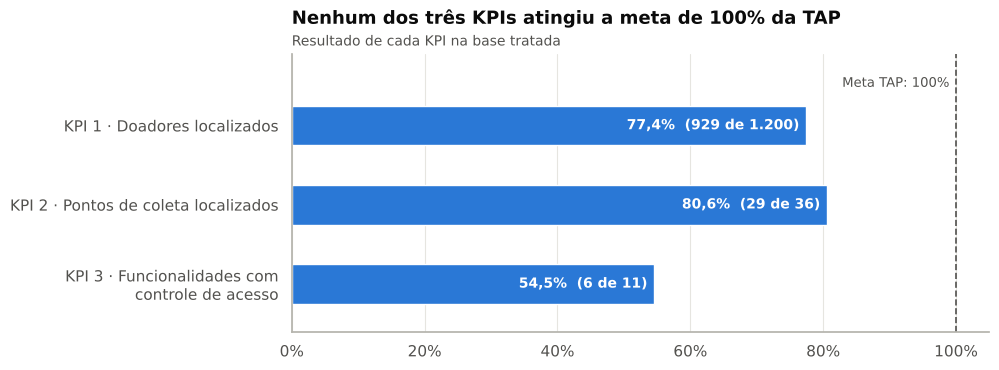

In [17]:
# Gráfico 1 — Barras: KPIs x meta da TAP
fig, ax = plt.subplots(figsize=(9, 3.6))
rotulos_kpi = ['KPI 1 · Doadores localizados', 'KPI 2 · Pontos de coleta localizados',
               'KPI 3 · Funcionalidades com\ncontrole de acesso']
y = np.arange(len(kpis))[::-1]
ax.barh(y, kpis['Resultado'], color=AZUL, height=0.5)
ax.axvline(1.0, color=TEXTO_SECUNDARIO, linestyle='--', linewidth=1.2)
ax.text(0.99, y.max() + 0.45, 'Meta TAP: 100%', ha='right', va='bottom', fontsize=9.5, color=TEXTO_SECUNDARIO)
for yi, (_, linha) in zip(y, kpis.iterrows()):
    ax.text(linha['Resultado'] - 0.01, yi, f"{pct(linha['Resultado'])}  ({num(linha['Atendidos'])} de {num(linha['Total'])})",
            ha='right', va='center', color='white', fontsize=10, fontweight='bold')
ax.set_yticks(y, rotulos_kpi)
ax.set_xlim(0, 1.05)
ax.set_ylim(-0.6, y.max() + 0.9)
formato_pct(ax, 'x')
ax.grid(axis='y', visible=False)
ax.set_title('Nenhum dos três KPIs atingiu a meta de 100% da TAP', pad=22)
subtitulo(ax, 'Resultado de cada KPI na base tratada')
salvar(fig, 'grafico1_kpis_vs_meta')
plt.show()

**Gráfico 1 (barras):** nenhum KPI atingiu a meta. O KPI 3 (segurança) é o mais distante, com 45,5 p.p. de diferença; o KPI 1 é o que tem mais registros pendentes (271 doadores).

,cadastros,localizados,taxa_quinzena,taxa_acumulada
quinzena,,,,
1ª ago,172,143,"83,1%","83,1%"
2ª ago,194,165,"85,1%","84,2%"
1ª set,184,137,"74,5%","80,9%"
2ª set,201,162,"80,6%","80,8%"
1ª out,219,150,"68,5%","78,0%"
2ª out,230,172,"74,8%","77,4%"


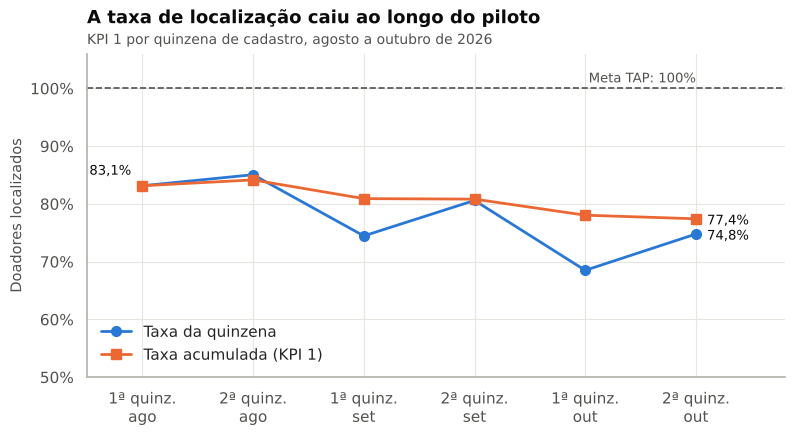

In [18]:
# Gráfico 2 — Linhas: evolução quinzenal do KPI 1
quinzena = np.where(doadores['data_cadastro'].dt.day <= 15, '1ª', '2ª')
meses = {8: 'ago', 9: 'set', 10: 'out'}
doadores['quinzena'] = [f'{q} {meses[m]}' for q, m in zip(quinzena, doadores['data_cadastro'].dt.month)]
ordem_quinzenas = [f'{q} {m}' for m in ['ago', 'set', 'out'] for q in ['1ª', '2ª']]
evolucao = (doadores.groupby('quinzena').agg(cadastros=('id_doador', 'count'),
                                             localizados=('localizado', 'sum'))
            .reindex(ordem_quinzenas))
evolucao['taxa_quinzena'] = evolucao['localizados'] / evolucao['cadastros']
evolucao['taxa_acumulada'] = evolucao['localizados'].cumsum() / evolucao['cadastros'].cumsum()
display(formatar(evolucao))

fig, ax = plt.subplots(figsize=(9, 4.2))
x = np.arange(len(evolucao))
ax.plot(x, evolucao['taxa_quinzena'], color=AZUL, linewidth=2, marker='o', markersize=7,
        label='Taxa da quinzena')
ax.plot(x, evolucao['taxa_acumulada'], color=LARANJA, linewidth=2, marker='s', markersize=7,
        label='Taxa acumulada (KPI 1)')
ax.axhline(1.0, color=TEXTO_SECUNDARIO, linestyle='--', linewidth=1.2)
ax.text(len(x) - 1, 1.005, 'Meta TAP: 100%', ha='right', va='bottom', fontsize=9.5, color=TEXTO_SECUNDARIO)
ax.annotate(pct(evolucao['taxa_quinzena'].iloc[-1]), (x[-1], evolucao['taxa_quinzena'].iloc[-1]),
            textcoords='offset points', xytext=(8, -4), color=TEXTO, fontsize=9.5)
ax.annotate(pct(evolucao['taxa_acumulada'].iloc[-1]), (x[-1], evolucao['taxa_acumulada'].iloc[-1]),
            textcoords='offset points', xytext=(8, -4), color=TEXTO, fontsize=9.5)
ax.annotate(pct(evolucao['taxa_quinzena'].iloc[0]), (x[0], evolucao['taxa_quinzena'].iloc[0]),
            textcoords='offset points', xytext=(-8, 8), ha='right', color=TEXTO, fontsize=9.5)
ax.set_xticks(x, [f'{q} quinz.\n{m}' for q, m in (rotulo.split() for rotulo in ordem_quinzenas)])
ax.set_xlim(-0.5, len(x) - 0.2)
ax.set_ylim(0.5, 1.06)
formato_pct(ax)
ax.set_ylabel('Doadores localizados')
ax.legend(loc='lower left')
ax.set_title('A taxa de localização caiu ao longo do piloto', pad=22)
subtitulo(ax, 'KPI 1 por quinzena de cadastro, agosto a outubro de 2026')
salvar(fig, 'grafico2_evolucao_kpi1')
plt.show()

**Gráfico 2 (linhas):** a taxa caiu de 83,1% na 1ª quinzena de agosto para 74,8% na 2ª quinzena de outubro (mínimo de 68,5% na 1ª de outubro). A queda acompanha o aumento dos cadastros feitos em campanhas presenciais. Sem ação no cadastro, o KPI 1 se afasta da meta à medida que a divulgação cresce.

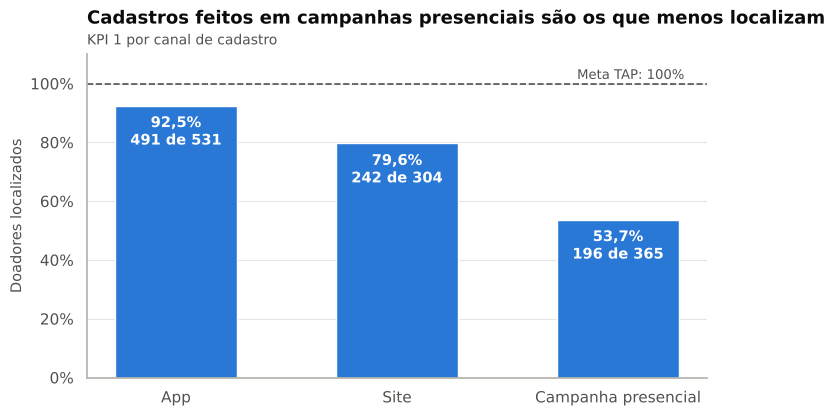

In [19]:
# Gráfico 3 — Barras: KPI 1 por canal de cadastro
ordem_canal = kpi1_canal.sort_values('taxa_localizacao', ascending=False)
fig, ax = plt.subplots(figsize=(8, 4.2))
barras = ax.bar(ordem_canal.index, ordem_canal['taxa_localizacao'], color=AZUL, width=0.55)
ax.axhline(1.0, color=TEXTO_SECUNDARIO, linestyle='--', linewidth=1.2)
ax.text(2.3, 1.005, 'Meta TAP: 100%', ha='right', va='bottom', fontsize=9.5, color=TEXTO_SECUNDARIO)
for barra, (_, linha) in zip(barras, ordem_canal.iterrows()):
    ax.text(barra.get_x() + barra.get_width() / 2, barra.get_height() - 0.03,
            f"{pct(linha['taxa_localizacao'])}\n{num(linha['localizados'])} de {num(linha['cadastros'])}",
            ha='center', va='top', fontsize=10.5, color='white', fontweight='bold')
ax.set_ylim(0, 1.1)
formato_pct(ax)
ax.set_ylabel('Doadores localizados')
ax.grid(axis='x', visible=False)
ax.set_title('Cadastros feitos em campanhas presenciais são os que menos localizam', pad=22)
subtitulo(ax, 'KPI 1 por canal de cadastro')
salvar(fig, 'grafico3_kpi1_por_canal')
plt.show()

**Gráfico 3 (barras):** o aplicativo, que obtém o endereço com mais precisão, localiza 92,5% dos doadores. O site localiza 79,6%, e a campanha presencial, em que o formulário é digitado depois, apenas 53,7%.

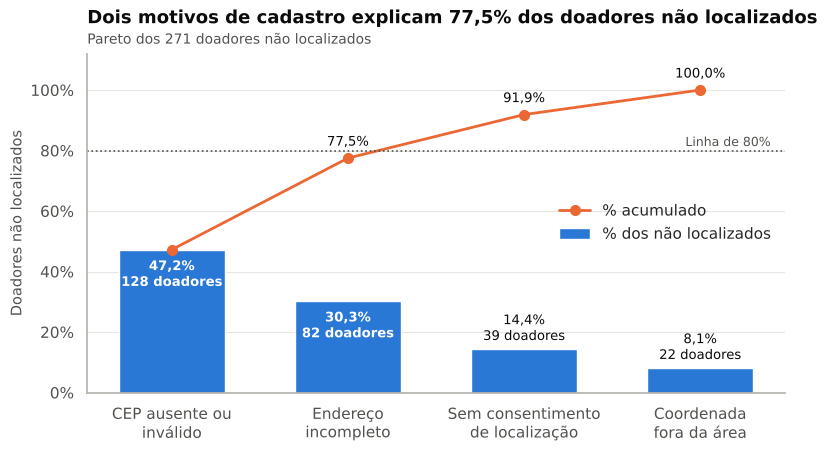

In [20]:
# Gráfico 4 — Pareto: motivos de não localização (barras e linha no mesmo eixo, em %)
fig, ax = plt.subplots(figsize=(9, 4.4))
x = np.arange(len(motivos))
ax.bar(x, motivos['participacao'], color=AZUL, width=0.6, label='% dos não localizados')
ax.plot(x, motivos['acumulado'], color=LARANJA, linewidth=2, marker='o', markersize=7, label='% acumulado')
ax.axhline(0.8, color=TEXTO_SECUNDARIO, linestyle=':', linewidth=1.2)
ax.text(len(x) - 0.6, 0.805, 'Linha de 80%', ha='right', va='bottom', fontsize=9, color=TEXTO_SECUNDARIO)
for xi, (_, linha) in zip(x, motivos.iterrows()):
    rotulo = f"{pct(linha['participacao'])}\n{linha['doadores']} doadores"
    if linha['participacao'] > 0.2:   # barra alta: rótulo dentro da barra
        ax.text(xi, linha['participacao'] - 0.03, rotulo, ha='center', va='top', fontsize=9.5,
                color='white', fontweight='bold')
    else:
        ax.text(xi, linha['participacao'] + 0.015, rotulo, ha='center', va='bottom', fontsize=9.5, color=TEXTO)
    if xi > 0:                        # no primeiro motivo o acumulado é igual à barra
        ax.annotate(pct(linha['acumulado']), (xi, linha['acumulado']), textcoords='offset points',
                    xytext=(0, 9), ha='center', fontsize=9.5, color=TEXTO)
ax.set_xticks(x, [m.replace(' ou ', ' ou\n').replace(' de loc', '\nde loc').replace(' fora', '\nfora')
                  .replace('o incompleto', 'o\nincompleto') for m in motivos['motivo']])
ax.set_ylim(0, 1.12)
formato_pct(ax)
ax.set_ylabel('Doadores não localizados')
ax.grid(axis='x', visible=False)
ax.legend(loc='center right')
ax.set_title(f"Dois motivos de cadastro explicam {pct(motivos.loc[1, 'acumulado'])} dos doadores não localizados",
             pad=22)
subtitulo(ax, f"Pareto dos {int(motivos['doadores'].sum())} doadores não localizados")
salvar(fig, 'grafico4_pareto_motivos')
plt.show()

**Gráfico 4 (Pareto):** dois motivos, *CEP ausente ou inválido* e *endereço incompleto*, explicam 77,5% dos doadores não localizados, perto da regra 80/20. Ambos são corrigíveis com validação obrigatória no momento do cadastro. Os casos sem consentimento (14,4%) não devem ser "corrigidos": pela LGPD, a alternativa é oferecer busca manual por CEP, sem armazenar a localização.

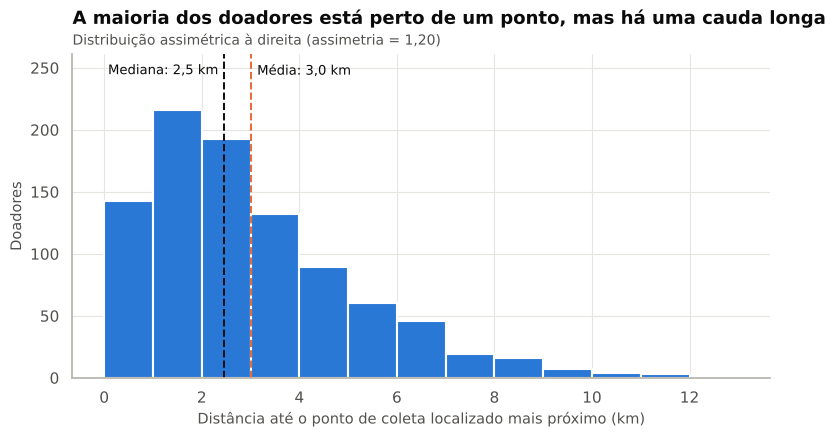

In [21]:
# Gráfico 5 — Histograma: distância até o ponto de coleta mais próximo
fig, ax = plt.subplots(figsize=(9, 4.2))
sns.histplot(dist, binwidth=1, binrange=(0, np.ceil(dist.max())), color=AZUL, edgecolor='white',
             linewidth=1.5, alpha=1, ax=ax)
topo = ax.get_ylim()[1] * 1.15
ax.set_ylim(0, topo)
for valor, nome, lado in [(dist.median(), 'Mediana', 'right'), (dist.mean(), 'Média', 'left')]:
    ax.axvline(valor, color=LARANJA if nome == 'Média' else TEXTO, linestyle='--', linewidth=1.4)
    ax.text(valor + (0.12 if lado == 'left' else -0.12), topo * 0.97, f'{nome}: {valor:.1f} km'.replace('.', ','),
            ha=lado, va='top', fontsize=9.5, color=TEXTO)
ax.set_xlabel('Distância até o ponto de coleta localizado mais próximo (km)')
ax.set_ylabel('Doadores')
ax.set_title('A maioria dos doadores está perto de um ponto, mas há uma cauda longa', pad=22)
subtitulo(ax, f'Distribuição assimétrica à direita (assimetria = {assimetria:.2f})'.replace('.', ','))
salvar(fig, 'grafico5_histograma_distancia')
plt.show()

**Gráfico 5 (histograma):** a maioria dos doadores está a menos de 4 km de um ponto, mas a cauda à direita chega a 12,85 km. É a assimetria medida na seção 2.2.

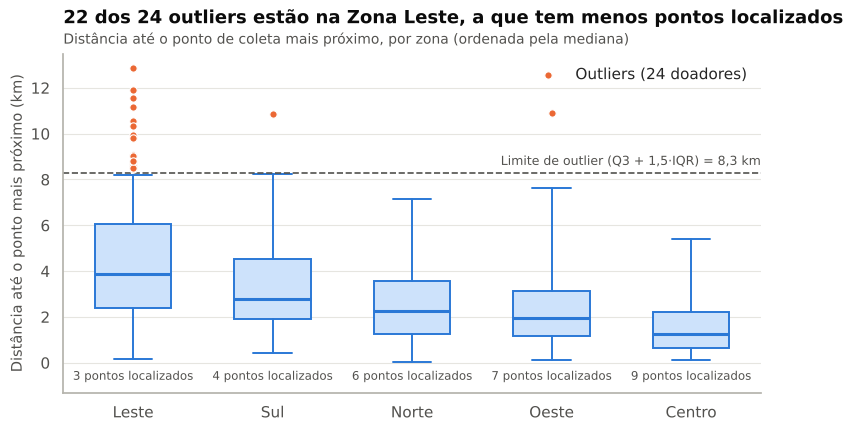

In [22]:
# Gráfico 6 — Boxplot: distância por zona, com os outliers da regra do IQR
ordem_zona = desc_zona.index.tolist()
# Caixa = Q1 a Q3 de cada zona; bigodes vão até o maior valor que NÃO é outlier pela regra do IQR (2.2)
caixas = []
for zona in ordem_zona:
    valores = localizados.loc[localizados['zona'] == zona, 'distancia_km']
    sem_outlier = valores[valores <= limite_superior]
    caixas.append({'label': zona, 'q1': valores.quantile(0.25), 'med': valores.median(),
                   'q3': valores.quantile(0.75), 'whislo': valores.min(), 'whishi': sem_outlier.max()})
fig, ax = plt.subplots(figsize=(9, 4.4))
ax.bxp(caixas, positions=range(len(ordem_zona)), widths=0.55, showfliers=False, patch_artist=True,
       boxprops={'facecolor': '#cde2fb', 'edgecolor': AZUL, 'linewidth': 1.4},
       medianprops={'color': AZUL, 'linewidth': 2.2},
       whiskerprops={'color': AZUL, 'linewidth': 1.4}, capprops={'color': AZUL, 'linewidth': 1.4})
ax.set_xticks(range(len(ordem_zona)), ordem_zona)
ax.scatter([ordem_zona.index(z) for z in outliers['zona']], outliers['distancia_km'], color=LARANJA,
           s=28, zorder=3, edgecolor='white', linewidth=0.8, label=f'Outliers ({len(outliers)} doadores)')
ax.axhline(limite_superior, color=TEXTO_SECUNDARIO, linestyle='--', linewidth=1.2)
ax.text(len(ordem_zona) - 0.5, limite_superior + 0.2,
        f'Limite de outlier (Q3 + 1,5·IQR) = {limite_superior:.1f} km'.replace('.', ',', 1),
        ha='right', va='bottom', fontsize=9, color=TEXTO_SECUNDARIO)
for i, zona in enumerate(ordem_zona):
    ax.text(i, -0.35, f"{int(pontos_zona.loc[zona, 'localizados'])} pontos localizados",
            ha='center', va='top', fontsize=8.5, color=TEXTO_SECUNDARIO)
ax.set_xlabel('')
ax.set_ylabel('Distância até o ponto mais próximo (km)')
ax.set_ylim(-1.3, None)
ax.grid(axis='x', visible=False)
ax.legend(loc='upper right')
zona_top = outliers_zona.iloc[0]
ax.set_title(f"{zona_top['outliers']} dos {len(outliers)} outliers estão na Zona {zona_top['zona']}, "
             f"a que tem menos pontos localizados", pad=22)
subtitulo(ax, 'Distância até o ponto de coleta mais próximo, por zona (ordenada pela mediana)')
salvar(fig, 'grafico6_boxplot_distancia_zona')
plt.show()

**Gráfico 6 (boxplot):** a Zona Leste tem a maior mediana e a maior dispersão, e concentra quase todos os outliers. As zonas ficam em ordem inversa à quantidade de pontos localizados: quanto menos pontos, maior a distância.

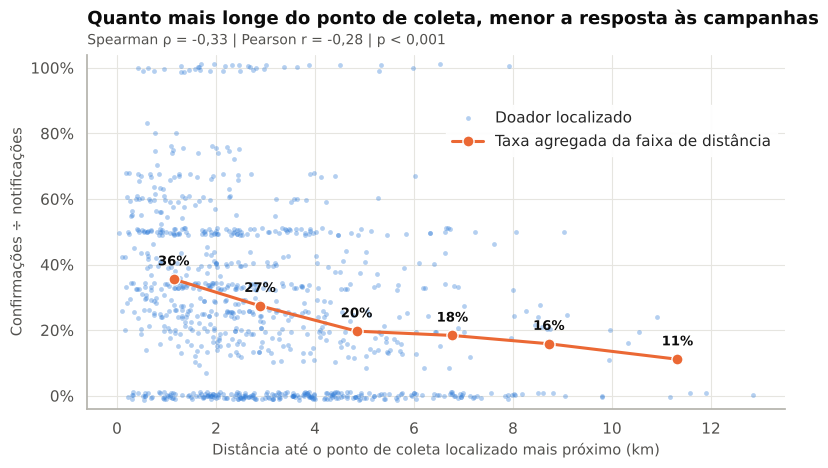

In [23]:
# Gráfico 7 — Dispersão: distância x taxa de resposta às campanhas
fig, ax = plt.subplots(figsize=(9, 4.6))
deslocamento = np.random.RandomState(7).uniform(-0.012, 0.012, len(base_corr))  # só para separar pontos sobrepostos
ax.scatter(base_corr['distancia_km'], base_corr['taxa_resposta'] + deslocamento, s=12, color=AZUL,
           alpha=0.35, linewidth=0, label='Doador localizado')
ax.plot(por_faixa['distancia_media'], por_faixa['taxa_resposta'], color=LARANJA, linewidth=2.2,
        marker='o', markersize=8, markeredgecolor='white', label='Taxa agregada da faixa de distância')
for _, linha in por_faixa.iterrows():
    ax.annotate(pct(linha['taxa_resposta'], 0), (linha['distancia_media'], linha['taxa_resposta']),
                textcoords='offset points', xytext=(0, 10), ha='center', fontsize=9.5, color=TEXTO,
                fontweight='bold')
ax.set_ylim(-0.04, 1.04)
formato_pct(ax)
ax.set_xlabel('Distância até o ponto de coleta localizado mais próximo (km)')
ax.set_ylabel('Confirmações ÷ notificações')
ax.legend(loc='upper right', bbox_to_anchor=(1, 0.88), frameon=True, facecolor='white', edgecolor='white',
          framealpha=0.95)
ax.set_title('Quanto mais longe do ponto de coleta, menor a resposta às campanhas', pad=22)
subtitulo(ax, f'Spearman ρ = {spearman_rho:.2f} | Pearson r = {pearson_r:.2f} | p < 0,001'.replace('.', ','))
salvar(fig, 'grafico7_dispersao_distancia_resposta')
plt.show()

**Gráfico 7 (dispersão):** cada ponto azul é um doador. Os valores individuais variam muito, o que explica a correlação moderada, mas a linha da taxa agregada desce de forma consistente a cada faixa de distância.

---
## 2.4 Análise crítica exigida (conexão com a Etapa 1)

> **Pergunta obrigatória:** *"Baseado nas correlações estatísticas, nos outliers encontrados e no principal KPI calculado, qual é o maior gargalo operacional da empresa que vocês escolheram? Explique como esses dados numéricos justificam as metas e o escopo que o grupo definiu no Termo de Abertura (TAP) na Disciplina 1."*

O maior gargalo operacional do Conecta Sangue é a **qualidade do endereço informado no cadastro**, que impede o sistema de localizar quase um em cada quatro doadores. O principal KPI, a taxa de localização de doadores, ficou em **77,4%** (929 de 1.200), 22,6 pontos percentuais abaixo da meta de 100% da TAP, e caiu ao longo do piloto (de 83,1% na 1ª quinzena de agosto para 74,8% na 2ª de outubro). O Pareto mostra que CEP ausente ou inválido e endereço incompleto explicam 77,5% dos 271 doadores não localizados, e o problema não é equilibrado: as campanhas presenciais têm 30,4% dos cadastros, mas 62,4% dos não localizados (χ² = 187,1; p < 0,001). O gargalo afeta diretamente a mobilidade: a correlação entre distância e resposta às campanhas é negativa (Spearman ρ = −0,33; p < 0,001), com a resposta caindo de 35,5% entre doadores a até 2 km de um ponto para 11,1% entre os que estão a 10 km ou mais, e os doadores não localizados respondem a só 10,7% das notificações, contra 28,4% dos localizados. Os 24 outliers de distância (acima de 8,31 km) estão quase todos (91,7%) na Zona Leste, a zona com mais cadastros e onde metade dos pontos de coleta cadastrados não está localizada (KPI 2 = 80,6%; só 61,5% das unidades móveis localizadas).

Esses números justificam as metas e o escopo da TAP. A meta de localizar 100% dos usuários e pontos de coleta ataca exatamente o gargalo: um doador não localizado não recebe campanhas por proximidade nem é orientado ao ponto mais perto, e um ponto não localizado cria vazios de cobertura como o da Zona Leste. Isso confirma no escopo o cadastro de doadores (com CEP e endereço obrigatórios e validados, principalmente na digitação dos formulários de campanha), o cadastro e localização de pontos de coleta (incluindo as unidades móveis) e a divulgação de campanhas. Os dados também confirmam o que ficou fora do escopo: a distância pesa na decisão de doar, mas o problema se resolve com informação e localização, e não com transporte de doadores ou com a substituição dos sistemas dos hemocentros. Por fim, a meta de segurança precisa avançar junto: a cobertura de controle de acesso é de **54,5%** (6 de 11 funcionalidades), e entre as que não têm proteção completa estão justamente as que usam a localização do doador (busca de pontos próximos e notificação por proximidade). Aumentar o KPI 1 sem cumprir a meta de 100% de controle de acesso ampliaria a exposição de dados pessoais, o que confirma a proteção de dados como item obrigatório do escopo.

Os números citados na análise crítica são recalculados pela célula abaixo.

In [24]:
# Números usados na análise crítica (2.4) — gerados pelo próprio código, para rastreabilidade
canal_pior = kpi1_canal.index[0]
zona_mais_outliers = outliers_zona.iloc[0]
RESUMO = {
    'linhas_brutas_doadores': len(doadores_bruto), 'doadores': len(doadores),
    'linhas_brutas_pontos': len(pontos_bruto), 'pontos': len(pontos),
    'kpi1': kpis.loc[0, 'Resultado'], 'kpi1_atendidos': kpis.loc[0, 'Atendidos'],
    'kpi1_faltam': kpis.loc[0, 'Faltam para a meta'],
    'kpi2': kpis.loc[1, 'Resultado'], 'kpi2_atendidos': kpis.loc[1, 'Atendidos'],
    'kpi3': kpis.loc[2, 'Resultado'], 'kpi3_atendidos': kpis.loc[2, 'Atendidos'],
    'kpi3_total': kpis.loc[2, 'Total'],
    'canal_pior': canal_pior, 'canal_pior_taxa': kpi1_canal.loc[canal_pior, 'taxa_localizacao'],
    'canal_pior_part_cadastros': kpi1_canal.loc[canal_pior, 'participacao_nos_cadastros'],
    'canal_pior_part_nao_loc': kpi1_canal.loc[canal_pior, 'participacao_nos_nao_localizados'],
    'app_taxa': kpi1_canal.loc['App', 'taxa_localizacao'],
    'site_taxa': kpi1_canal.loc['Site', 'taxa_localizacao'],
    'motivo1': motivos.loc[0, 'motivo'], 'motivo1_part': motivos.loc[0, 'participacao'],
    'motivo2': motivos.loc[1, 'motivo'], 'motivos_1_2_acum': motivos.loc[1, 'acumulado'],
    'quinzena_inicial': evolucao['taxa_quinzena'].iloc[0], 'quinzena_final': evolucao['taxa_quinzena'].iloc[-1],
    'dist_media': dist.mean(), 'dist_mediana': dist.median(), 'dist_desvio': dist.std(),
    'assimetria': assimetria, 'shapiro_p': shapiro_p, 'qui2': qui2, 'qui2_p': qui2_p, 'v_cramer': v_cramer,
    'pearson_r': pearson_r, 'pearson_p': pearson_p, 'spearman_rho': spearman_rho, 'spearman_p': spearman_p,
    'limite_outlier': limite_superior, 'n_outliers': len(outliers),
    'zona_outliers': zona_mais_outliers['zona'], 'zona_outliers_part': zona_mais_outliers['participacao'],
    'resposta_localizados': resposta_grupo.loc['Localizados', 'taxa de resposta'],
    'resposta_nao_localizados': resposta_grupo.loc['Não localizados', 'taxa de resposta'],
    'celulas_vazias_doadores': int(doadores_bruto.isna().sum().sum()),
    'grafias_canal': doadores_bruto['canal_cadastro'].nunique(),
    'q1': q1, 'q3': q3, 'iqr': iqr, 'n_corr': len(base_corr),
}
for chave, valor in RESUMO.items():
    print(f'{chave:28s} {valor:.4f}' if isinstance(valor, float) else f'{chave:28s} {valor}')

linhas_brutas_doadores       1236
doadores                     1200
linhas_brutas_pontos         38
pontos                       36
kpi1                         0.7742
kpi1_atendidos               929
kpi1_faltam                  271
kpi2                         0.8056
kpi2_atendidos               29
kpi3                         0.5455
kpi3_atendidos               6
kpi3_total                   11
canal_pior                   Campanha presencial
canal_pior_taxa              0.5370
canal_pior_part_cadastros    0.3042
canal_pior_part_nao_loc      0.6236
app_taxa                     0.9247
site_taxa                    0.7961
motivo1                      CEP ausente ou inválido
motivo1_part                 0.4723
motivo2                      Endereço incompleto
motivos_1_2_acum             0.7749
quinzena_inicial             0.8314
quinzena_final               0.7478
dist_media                   3.0165
dist_mediana                 2.4600
dist_desvio                  2.1426
assimetria      

---
## Bibliotecas utilizadas

| Biblioteca | Uso neste notebook |
|---|---|
| `pandas` | leitura dos CSV, limpeza, padronização, agregações e gravação dos dados tratados (ETL) |
| `numpy` | cálculos vetorizados (distância de Haversine, classificação dos motivos) e geração da base simulada |
| `scipy.stats` | assimetria, curtose, Shapiro-Wilk, qui-quadrado, Pearson e Spearman |
| `matplotlib` | construção e exportação dos 7 gráficos (PNG em `graficos/`) |
| `seaborn` | tema visual e histograma |

Todas já vêm instaladas no Google Colab. Para rodar em outro ambiente Jupyter: `pip install pandas numpy scipy matplotlib seaborn`.

**Para usar dados reais do protótipo:** substitua os três arquivos de `dados/brutos/` mantendo os mesmos nomes de colunas e execute tudo novamente. Os KPIs, as estatísticas e os gráficos são recalculados automaticamente.